In [1]:
!pip install -q -U medmnist

REG = "040"
SEED = int(REG[-2:])
d = int(REG[-1])
HOG_CELL = 8 if d % 2 == 0 else 16
GRID = 4 if d <= 4 else 6
print(f"seed={SEED}, HOG cell={HOG_CELL}x{HOG_CELL}, SIFT grid={GRID}x{GRID}")

seed=40, HOG cell=8x8, SIFT grid=4x4


In [16]:
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
from medmnist import BloodMNIST

KEEP = {1: 'eosinophil', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}
NAMES = list(KEEP.values())
rng = np.random.RandomState(SEED)

def load_split(split, n):
    ds = BloodMNIST(split=split, download=True, size=64)
    X, y = ds.imgs, ds.labels.ravel()
    imgs, labels = [], []
    for new, old in enumerate(KEEP):
        pick = rng.choice(np.where(y == old)[0], n, replace=False)
        for i in pick:
            gray = cv2.cvtColor(X[i], cv2.COLOR_RGB2GRAY)
            imgs.append(cv2.resize(gray, (128, 128)))
            labels.append(new)
    return np.array(imgs), np.array(labels)

Xtr, ytr = load_split('train', 100)
Xva, yva = load_split('val', 30)
Xte, yte = load_split('test', 30)   # don't use until Q4

for name, X, y in [('train', Xtr, ytr), ('val', Xva, yva), ('test', Xte, yte)]:
    print(name, X.shape, dict(zip(NAMES, np.bincount(y))))

train (400, 128, 128) {'eosinophil': np.int64(100), 'monocyte': np.int64(100), 'neutrophil': np.int64(100), 'platelet': np.int64(100)}
val (120, 128, 128) {'eosinophil': np.int64(30), 'monocyte': np.int64(30), 'neutrophil': np.int64(30), 'platelet': np.int64(30)}
test (120, 128, 128) {'eosinophil': np.int64(30), 'monocyte': np.int64(30), 'neutrophil': np.int64(30), 'platelet': np.int64(30)}


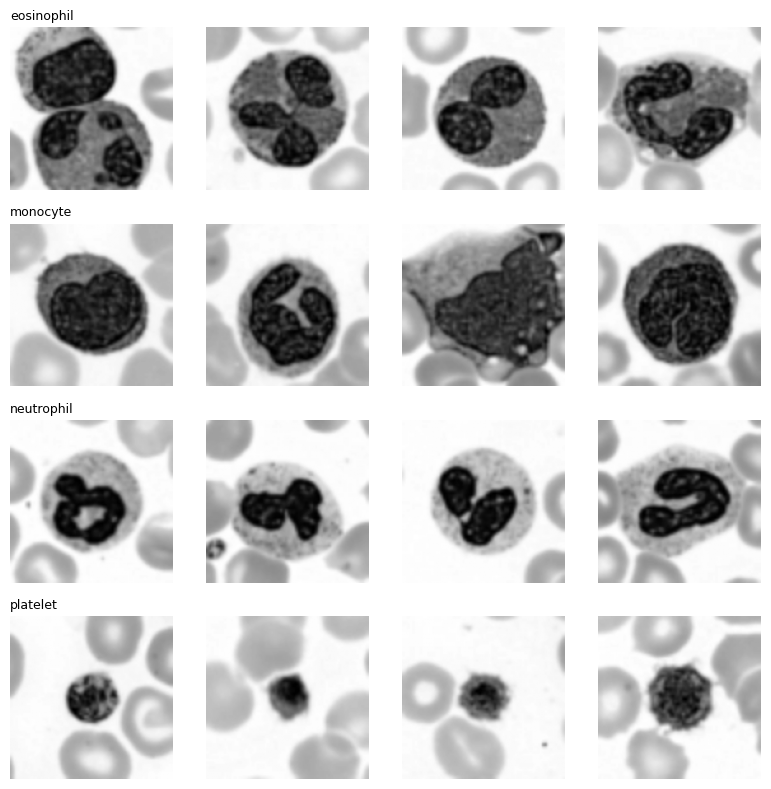

In [17]:
%matplotlib inline
fig, ax = plt.subplots(4, 4, figsize=(8, 8))
for c in range(4):
    for j, i in enumerate(np.where(ytr == c)[0][:4]):
        ax[c, j].imshow(Xtr[i], cmap='gray')
        ax[c, j].axis('off')
    ax[c, 0].set_title(NAMES[c], fontsize=9, loc='left')
plt.tight_layout()
plt.show()

Q2

HOG feature length (actual): 8100
By hand: 16 cells per side -> 15x15=225 blocks x 36 = 8100


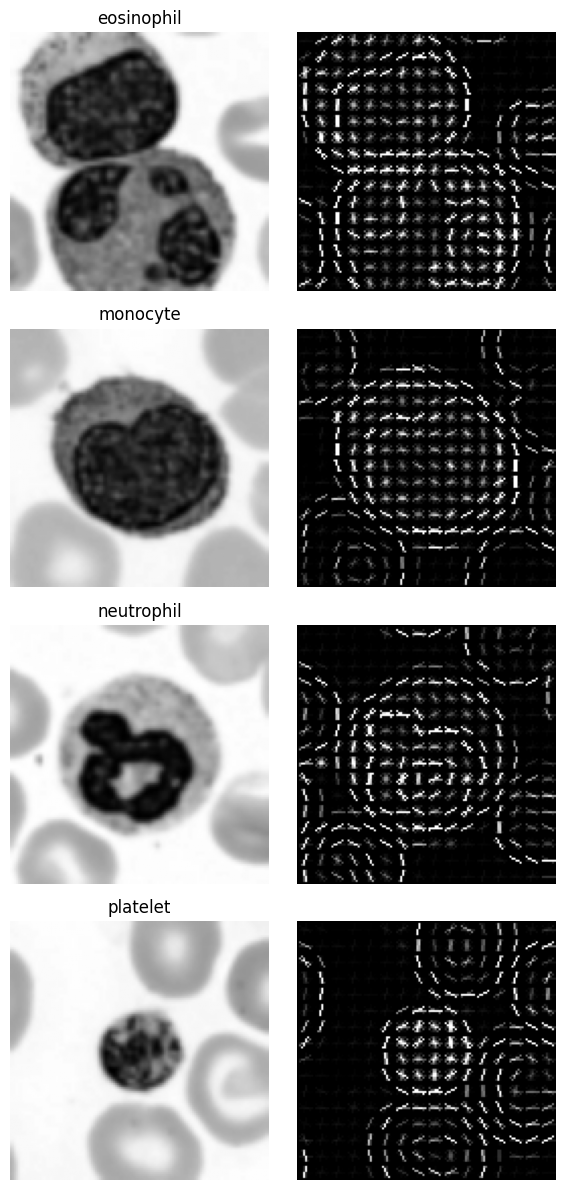

C=0.1: val acc=0.7250
C=1: val acc=0.7250
C=10: val acc=0.7250
Chosen C = 0.1
HOG+SVM (validation): accuracy=0.7250, macro-F1=0.7206
[[15  6  9  0]
 [ 5 24  1  0]
 [ 3  9 18  0]
 [ 0  0  0 30]]


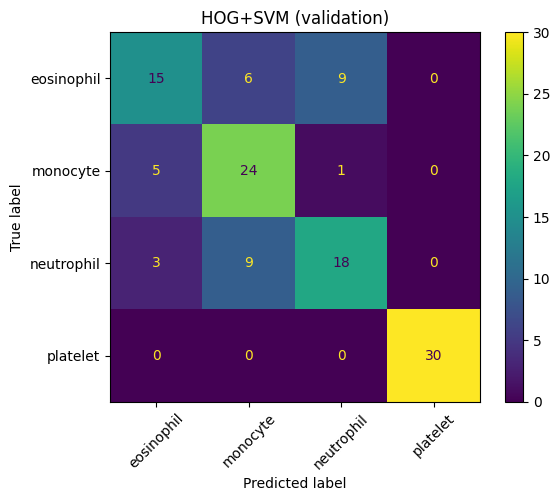

In [10]:
from skimage.feature import hog
from skimage import exposure

def hog_feat(img):
    return hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2), block_norm='L2-Hys', feature_vector=True)

H_tr = np.array([hog_feat(i) for i in Xtr])
H_va = np.array([hog_feat(i) for i in Xva])

cells = 128 // HOG_CELL
blocks = (cells - 1) ** 2
print("HOG feature length (actual):", H_tr.shape[1])
print(f"By hand: {cells} cells per side -> {cells-1}x{cells-1}={blocks} blocks x 36 =", blocks * 36)

fig, ax = plt.subplots(4, 2, figsize=(6, 12))
for c in range(4):
    img = Xtr[np.where(ytr == c)[0][0]]
    _, hi = hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                cells_per_block=(2, 2), visualize=True)
    ax[c, 0].imshow(img, cmap='gray'); ax[c, 0].set_title(NAMES[c]); ax[c, 0].axis('off')
    ax[c, 1].imshow(exposure.rescale_intensity(hi, in_range=(0, 10)), cmap='gray'); ax[c, 1].axis('off')
plt.tight_layout(); plt.show()

hog_model = fit_select_C(H_tr, ytr, H_va, yva)
cm_hog = report(hog_model, H_va, yva, "HOG+SVM (validation)")

Q3

avg=71.1, min=9, max=213, zero-keypoint images=0


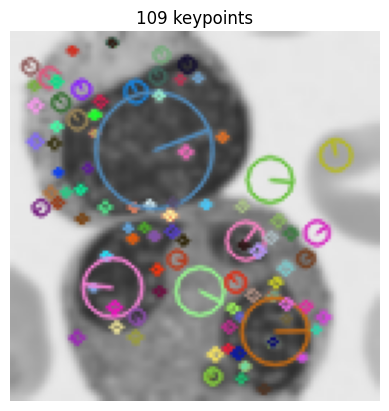

In [11]:
sift = cv2.SIFT_create()

counts = []
for img in Xtr:
    kp, des = sift.detectAndCompute(img, None)
    counts.append(len(kp))
counts = np.array(counts)
print(f"avg={counts.mean():.1f}, min={counts.min()}, max={counts.max()}, zero-keypoint images={(counts == 0).sum()}")

kp, _ = sift.detectAndCompute(Xtr[0], None)
vis = cv2.drawKeypoints(Xtr[0], kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(vis); plt.title(f"{len(kp)} keypoints"); plt.axis('off'); plt.show()

SIFT feature length (actual): 2048
By hand: 4x4=16 grid points x 128 = 2048
C=0.1: val acc=0.7417
C=1: val acc=0.7500
C=10: val acc=0.7500
Chosen C = 1
SIFT+SVM (validation): accuracy=0.7500, macro-F1=0.7529
[[19  7  4  0]
 [ 5 22  3  0]
 [ 8  1 21  0]
 [ 0  1  1 28]]


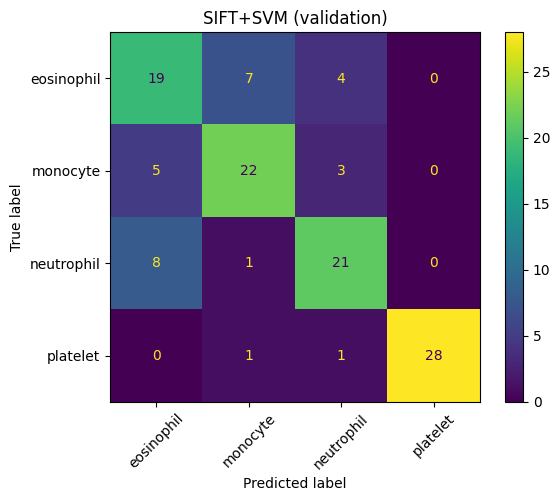

In [6]:
# Fixed 4x4 grid, keypoint size 32
pts = (np.arange(GRID) + 0.5) * (128 / GRID)
def grid_kps():
    return [cv2.KeyPoint(float(x), float(y), 32.0, 0.0) for y in pts for x in pts]

def sift_grid_feat(img):
    kps, des = sift.compute(img, grid_kps())
    assert des.shape == (GRID * GRID, 128), des.shape
    return des.flatten()

S_tr = np.array([sift_grid_feat(i) for i in Xtr])
S_va = np.array([sift_grid_feat(i) for i in Xva])
print("SIFT feature length (actual):", S_tr.shape[1])
print(f"By hand: {GRID}x{GRID}={GRID*GRID} grid points x 128 =", GRID * GRID * 128)

sift_model = fit_select_C(S_tr, ytr, S_va, yva)
cm_sift = report(sift_model, S_va, yva, "SIFT+SVM (validation)")

Q4

,Model,clean accuracy,rotated accuracy,noisy accuracy
0,HOG + SVM,0.6833,0.7417,0.2500
1,SIFT + SVM,0.6833,0.4917,0.7167


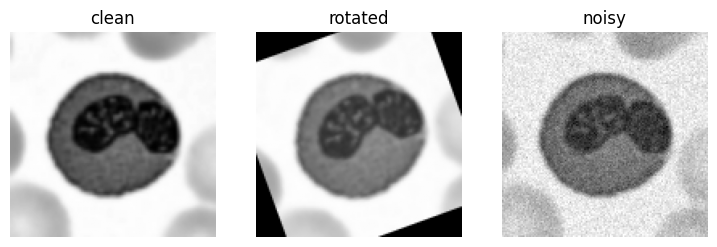

In [7]:
def rotate(img, deg=20):
    M = cv2.getRotationMatrix2D((64, 64), deg, 1.0)
    return cv2.warpAffine(img, M, (128, 128), borderMode=cv2.BORDER_CONSTANT, borderValue=0)

noise_rng = np.random.RandomState(SEED)
def add_noise(img, sigma=0.05):
    x = img.astype(np.float32) / 255.0
    x = np.clip(x + noise_rng.normal(0, sigma, x.shape), 0, 1)
    return (x * 255).round().astype(np.uint8)

cases = {
    'clean':   Xte,
    'rotated': np.array([rotate(i) for i in Xte]),
    'noisy':   np.array([add_noise(i) for i in Xte]),
}

rows = []
for name, model, fe in [('HOG + SVM', hog_model, hog_feat), ('SIFT + SVM', sift_model, sift_grid_feat)]:
    row = {'Model': name}
    for case, imgs in cases.items():
        F = np.array([fe(i) for i in imgs])
        row[f'{case} accuracy'] = round(accuracy_score(yte, model.predict(F)), 4)
    rows.append(row)
results = pd.DataFrame(rows)
display(results)

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, (k, v) in zip(ax, cases.items()):
    a.imshow(v[0], cmap='gray'); a.set_title(k); a.axis('off')
plt.show()

Q5

In [8]:
def top_confusion(cm, title):
    c = cm.copy().astype(float); np.fill_diagonal(c, 0)
    i, j = np.unravel_index(c.argmax(), c.shape)
    print(f"{title}: true {NAMES[i]} predicted as {NAMES[j]} ({int(c[i, j])} times)")

top_confusion(cm_hog, "HOG")
top_confusion(cm_sift, "SIFT")

HOG: true eosinophil predicted as neutrophil (9 times)
SIFT: true neutrophil predicted as eosinophil (8 times)
